# Evolution des metriques RAGAS

Lecture simple du fichier `nba_rag_eval_versions.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

csv_path = Path("nba_rag_eval_versions.csv")
if not csv_path.exists():
    csv_path = Path("reports/nba_rag_eval_versions.csv")

df = pd.read_csv(csv_path)
df = df[df["include_in_timeline"].astype(str).str.lower().eq("true")].copy()
df["version_number"] = pd.to_numeric(df["version_number"])
df = df.sort_values("version_number")

In [2]:
df[["version", "experiment_name"]]

,version,experiment_name
0,v1,phase 1
1,v2,pydantic_ai_constrained_rag
2,v3,pydantic_ai_constrained_rag
3,v4,pydantic_ai_constrained_rag
4,v5,pydantic_ai_constrained_rag_observability
6,v6,pydantic_evals_refactor
7,v7,with_sql_strategy


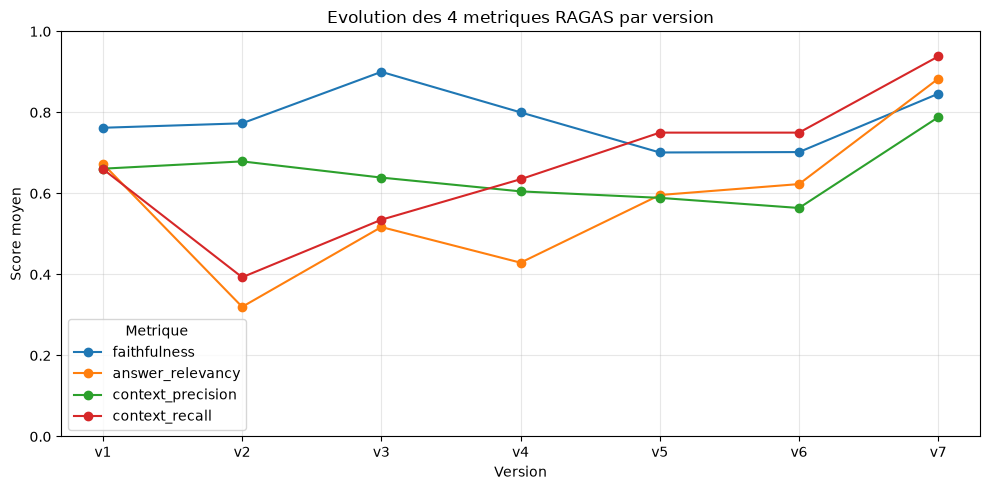

In [3]:
metrics = [
    "faithfulness",
    "answer_relevancy",
    "context_precision",
    "context_recall",
]

for metric in metrics:
    df[metric] = pd.to_numeric(df[metric], errors="coerce")

ax = df.plot(
    x="version",
    y=metrics,
    marker="o",
    figsize=(10, 5),
)
ax.set_title("Evolution des 4 metriques RAGAS par version")
ax.set_xlabel("Version")
ax.set_ylabel("Score moyen")
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend(title="Metrique")
plt.tight_layout()